================================================================
CAPSTONE PROJECT 1 - WALMART SALES INSIGHTS AND 12-WEEK FORECAST
================================================================


> **Data note:** This notebook uses the genuine `Walmart DataSet.csv` supplied with the project. The deployment `model.pkl` is trained from this dataset.

# Problem Statement

# Project Objective

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

# Loading data and converting the date and time format of datae column

In [2]:
walmart = pd.read_csv('Walmart DataSet.csv')
walmart['Date'] = pd.to_datetime(walmart['Date'], dayfirst=True, errors='coerce')

walmart


,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,2012-01-06,1610665.02,1,54.53,2.964,199.653492,7.900
1,1,2012-01-13,1620561.48,0,57.64,2.974,199.964821,7.845
2,1,2012-01-20,1608751.88,0,59.75,3.009,200.154171,7.829
3,1,2012-01-27,1603831.78,0,59.88,2.954,200.054454,7.774
4,1,2012-02-03,1565124.16,0,57.62,3.062,200.045222,7.877
...,...,...,...,...,...,...,...,...
2695,45,2013-01-25,714797.39,0,54.39,3.475,207.403588,7.107
2696,45,2013-02-01,725038.67,0,53.48,3.476,207.364095,6.865
2697,45,2013-02-08,713931.65,0,65.49,3.422,207.548987,6.983
2698,45,2013-02-15,712836.66,0,56.14,3.436,207.378080,7.082


# Data Description

# Basic Data Checking

In [3]:
print('Shape:', walmart.shape)
print('\nMissing values:\n', walmart.isna().sum())
print('\nDuplicate rows:', walmart.duplicated().sum())
print('\nDate range:', walmart['Date'].min(), 'to', walmart['Date'].max())

Shape: (2700, 8)

Missing values:
 Store           0
Date            0
Weekly_Sales    0
Holiday_Flag    0
Temperature     0
Fuel_Price      0
CPI             0
Unemployment    0
dtype: int64

Duplicate rows: 0

Date range: 2012-01-06 00:00:00 to 2013-02-22 00:00:00


# 2. DATA PREPROCESSING : Cleaning and Sorting the Walmart Data

In [4]:

walmart = walmart.drop_duplicates().copy()

walmart = walmart.dropna(
    subset=['Store', 'Date', 'Weekly_Sales']
)

walmart = walmart.sort_values(['Store', 'Date'])

print('\nshape after cleaning:', walmart.shape)



shape after cleaning: (2700, 8)


# 3. USEFUL BUSINESS INSIGHTS : Store-wise Sales Summary

In [5]:


store_summary = walmart.groupby('Store').agg(
    Total_Sales=('Weekly_Sales', 'sum'),
    Average_Weekly_Sales=('Weekly_Sales', 'mean'),
    Maximum_Weekly_Sales=('Weekly_Sales', 'max'),
    Minimum_Weekly_Sales=('Weekly_Sales', 'min'),
    Weekly_Sales_Std=('Weekly_Sales', 'std')
).sort_values('Total_Sales', ascending=False)


In [6]:

print('Top 10 stores by total sales:')
print(store_summary.head(10))

print('\nBottom 10 stores by total sales:')
print(store_summary.tail(10))

Top 10 stores by total sales:
        Total_Sales  ...  Weekly_Sales_Std
Store                ...                  
3      1.310727e+08  ...      92100.026971
39     1.279283e+08  ...     106668.140931
7      1.238116e+08  ...     101275.787530
28     1.224126e+08  ...      71671.507948
18     1.211510e+08  ...     107485.959071
24     1.184715e+08  ...      87607.589261
27     1.152966e+08  ...     118596.910311
20     1.110173e+08  ...     113021.860477
41     1.102060e+08  ...      94474.545724
11     1.071856e+08  ...     105061.212332

[10 rows x 5 columns]

Bottom 10 stores by total sales:
       Total_Sales  ...  Weekly_Sales_Std
Store               ...                  
14     44251295.44  ...      34047.842803
45     42036438.35  ...      38157.286880
12     38800637.42  ...      34360.562992
31     35931969.14  ...      29264.547222
16     33933909.15  ...      24143.280397
9      31641665.34  ...      29478.248759
26     28521318.76  ...      18586.943520
40     26345273.73 

# Holiday insight : Finding Average weekly Sales on Holidays and  Non-Holidays

To compare the average weekly sales for holiday and non-holiday weeks.

In [7]:

holiday_sales = walmart.groupby('Holiday_Flag')['Weekly_Sales'].mean()


In [8]:
holiday_sales.index = holiday_sales.index.map({
    0: 'Non-Holiday',
    1: 'Holiday'
})

print(holiday_sales)

Holiday_Flag
Non-Holiday    1.262406e+06
Holiday        1.259336e+06
Name: Weekly_Sales, dtype: float64


# Inferences from the Analysis

# Finding Correlations with Weekly Sales

In [9]:

print('Correlations with Weekly Sales:')
print(
    walmart[['Weekly_Sales', 'Temperature', 'Fuel_Price','CPI', 'Unemployment']
    ].corr()['Weekly_Sales'].sort_values(ascending=False)
)


Correlations with Weekly Sales:
Weekly_Sales    1.000000
Temperature     0.113033
CPI             0.045850
Unemployment   -0.036276
Fuel_Price     -0.142831
Name: Weekly_Sales, dtype: float64


# Total Weekly Sales for each month

In [10]:

Total_Weekly_Sales_Per_month = (
    walmart
    .set_index('Date')['Weekly_Sales']
    .resample('ME')
    .sum()
)

Total_Weekly_Sales_Per_month

Date
2012-01-31    2.313157e+08
2012-02-29    2.295793e+08
2012-03-31    2.881527e+08
2012-04-30    2.308502e+08
2012-05-31    2.336270e+08
2012-06-30    2.979454e+08
2012-07-31    2.366438e+08
2012-08-31    2.857463e+08
2012-09-30    2.170534e+08
2012-10-31    2.115832e+08
2012-11-30    2.663401e+08
2012-12-31    2.222292e+08
2013-01-31    2.297930e+08
2013-02-28    2.269468e+08
Freq: ME, Name: Weekly_Sales, dtype: float64

In [11]:
# Alias used by the existing monthly sales plot cell.
monthly_sales = Total_Weekly_Sales_Per_month

# Plotting Monthly Sales Trend 

Using line chart to show how Walmart sales change month by month over time.

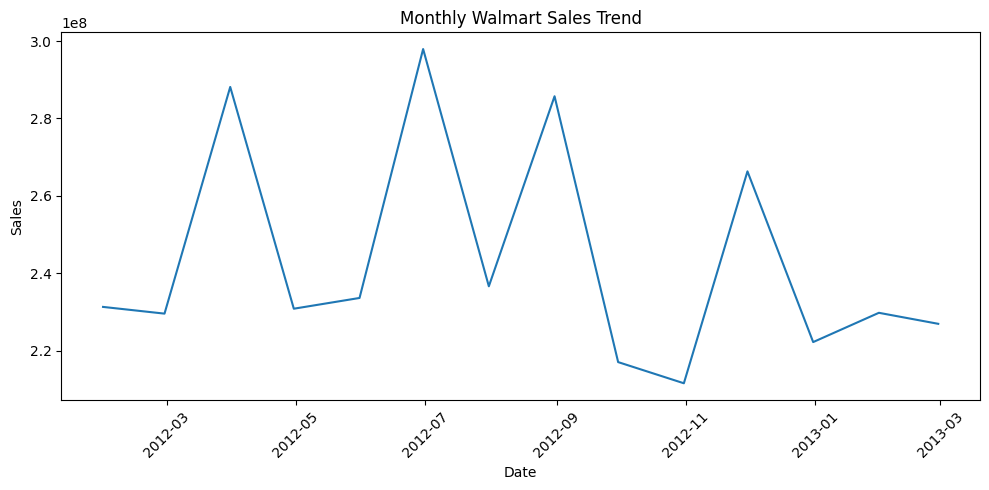

In [12]:
plt.figure(figsize=(10, 5))
plt.plot(monthly_sales)
plt.title('Monthly Walmart Sales Trend')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# FEATURE ENGINEERING : Creating Year, Month, and Week Columns

In [13]:
walmart['Year'] = walmart['Date'].dt.year
walmart['Month'] = walmart['Date'].dt.month
walmart['Week'] = walmart['Date'].dt.isocalendar().week.astype(int)

# Creating Previous week Sales value 

To create previous-week sales values for each store,
which helps analyze how past sales affect current/future sales.

In [14]:
walmart['Lag_1'] = walmart.groupby('Store')['Weekly_Sales'].shift(1)
walmart['Lag_2'] = walmart.groupby('Store')['Weekly_Sales'].shift(2)
walmart['Lag_4'] = walmart.groupby('Store')['Weekly_Sales'].shift(4)


# Calculating the Previous 4-Week Average Sales

In [15]:

walmart['Rolling_4'] = (
    walmart.groupby('Store')['Weekly_Sales']
    .shift(1)
    .rolling(4)
    .mean()
)
walmart



,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment,Year,Month,Week,Lag_1,Lag_2,Lag_4,Rolling_4
0,1,2012-01-06,1610665.02,1,54.53,2.964,199.653492,7.900,2012,1,1,NaN,NaN,NaN,NaN
1,1,2012-01-13,1620561.48,0,57.64,2.974,199.964821,7.845,2012,1,2,1610665.02,NaN,NaN,NaN
2,1,2012-01-20,1608751.88,0,59.75,3.009,200.154171,7.829,2012,1,3,1620561.48,1610665.02,NaN,NaN
3,1,2012-01-27,1603831.78,0,59.88,2.954,200.054454,7.774,2012,1,4,1608751.88,1620561.48,NaN,NaN
4,1,2012-02-03,1565124.16,0,57.62,3.062,200.045222,7.877,2012,2,5,1603831.78,1608751.88,1610665.02,1.610953e+06
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2695,45,2013-01-25,714797.39,0,54.39,3.475,207.403588,7.107,2013,1,4,713273.34,720227.21,685570.12,7.111732e+05
2696,45,2013-02-01,725038.67,0,53.48,3.476,207.364095,6.865,2013,2,5,714797.39,713273.34,725622.29,7.184801e+05
2697,45,2013-02-08,713931.65,0,65.49,3.422,207.548987,6.983,2013,2,6,725038.67,714797.39,720227.21,7.183342e+05
2698,45,2013-02-15,712836.66,0,56.14,3.436,207.378080,7.082,2013,2,7,713931.65,725038.67,713273.34,7.167603e+05


# Remove Missing Values from Walmart Data

In [16]:
model_data = walmart.dropna().copy()
model_data

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment,Year,Month,Week,Lag_1,Lag_2,Lag_4,Rolling_4
4,1,2012-02-03,1565124.16,0,57.62,3.062,200.045222,7.877,2012,2,5,1603831.78,1608751.88,1610665.02,1.610953e+06
5,1,2012-02-10,1497402.25,0,59.02,3.019,200.435633,7.845,2012,2,6,1565124.16,1603831.78,1620561.48,1.599567e+06
6,1,2012-02-17,1544180.92,0,60.85,3.001,200.589983,7.760,2012,2,7,1497402.25,1565124.16,1608751.88,1.568778e+06
7,1,2012-02-24,1498426.45,0,59.80,2.989,200.617820,7.775,2012,2,8,1544180.92,1497402.25,1603831.78,1.552635e+06
8,1,2012-03-02,1541480.08,0,64.90,3.031,200.743506,7.727,2012,3,9,1498426.45,1544180.92,1565124.16,1.526283e+06
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2695,45,2013-01-25,714797.39,0,54.39,3.475,207.403588,7.107,2013,1,4,713273.34,720227.21,685570.12,7.111732e+05
2696,45,2013-02-01,725038.67,0,53.48,3.476,207.364095,6.865,2013,2,5,714797.39,713273.34,725622.29,7.184801e+05
2697,45,2013-02-08,713931.65,0,65.49,3.422,207.548987,6.983,2013,2,6,725038.67,714797.39,720227.21,7.183342e+05
2698,45,2013-02-15,712836.66,0,56.14,3.436,207.378080,7.082,2013,2,7,713931.65,725038.67,713273.34,7.167603e+05


# Data Pre-processing Steps and Inspiration

# Store-wise Train–Test Split

Dividing each store’s time-series data into training data
and the last 12 months of testing data, 
while keeping the chronological order intact.

In [17]:
train_parts = []
test_parts = []

for store, data in model_data.groupby('Store'):

    data = data.sort_values('Date')

    if len(data) > 12:
        train_parts.append(data.iloc[:-12])
        test_parts.append(data.iloc[-12:])

train = pd.concat(train_parts)
test = pd.concat(test_parts)


# Selecting Features for the Machine Learning Model

creatingh a list of all the input columns that will be used as features (independent variables) for training the machine learning model.

In [18]:
features = [
    'Store',
    'Holiday_Flag',
    'Temperature',
    'Fuel_Price',
    'CPI',
    'Unemployment',
    'Year',
    'Month',
    'Week',
    'Lag_1',
    'Lag_2',
    'Lag_4',
    'Rolling_4'
]


In [19]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import StandardScaler

# Preparing Data and Training the Random Forest Model using " time based train_test_split "

In [20]:
X_train = train[features]
y_train = train['Weekly_Sales']

X_test = test[features]
y_test = test['Weekly_Sales']


model = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

# Model Prediction and Error Measurement

predicting values on unseen test data 
and calculates different error metrics 
to measure how accurate the model’s predictions are

In [21]:
pred = model.predict(X_test)

mae = mean_absolute_error(y_test, pred)
rmse = np.sqrt(mean_squared_error(y_test, pred))
mape = np.mean(np.abs((y_test - pred) / y_test)) * 100
wmape = np.sum(np.abs(y_test - pred)) / np.sum(np.abs(y_test)) * 100



In [22]:
print('MODEL PERFORMANCE')
print('MAE :', mae)
print('RMSE:', rmse)
print('MAPE:', mape)
print('WMAPE:', wmape)

MODEL PERFORMANCE
MAE : 30316.248243086357
RMSE: 40103.12367227895
MAPE: 2.519131409620195
WMAPE: 2.411122794472516


# Model Evaluation and Techniques

# Arranging Feature Importance from Highest to Lowest

identifying which input features are most important for the model
and display them in descending order of importance.

In [23]:
importance = pd.Series(model.feature_importances_,index=features
).sort_values(ascending=False)



In [24]:
print('Feature importance:')
print(importance)


Feature importance:
Lag_1           0.881285
Rolling_4       0.108187
Lag_2           0.006431
Lag_4           0.001534
Temperature     0.000514
Unemployment    0.000488
CPI             0.000450
Fuel_Price      0.000441
Week            0.000380
Store           0.000138
Month           0.000114
Holiday_Flag    0.000039
Year            0.000000
dtype: float64


# Creating Future Forecast data 

 so a trained forecasting model can predict the next 12 weeks of sales.

In [25]:
forecast_rows = []

for store in walmart['Store'].unique():

    Current_Store_records = walmart[walmart['Store'] == store].sort_values('Date').copy()

    for _ in range(12):

        last_date = Current_Store_records['Date'].max()
        next_date = last_date + pd.Timedelta(weeks=1)

        lag1 = Current_Store_records['Weekly_Sales'].iloc[-1]
        lag2 = Current_Store_records['Weekly_Sales'].iloc[-2]
        lag4 = Current_Store_records['Weekly_Sales'].iloc[-4]

        rolling4 = Current_Store_records['Weekly_Sales'].iloc[-4:].mean()

        row = pd.DataFrame([{
            'Store': store,
            'Holiday_Flag': 0,
            'Temperature': Current_Store_records['Temperature'].iloc[-1],
            'Fuel_Price': Current_Store_records['Fuel_Price'].iloc[-1],
            'CPI': Current_Store_records['CPI'].iloc[-1],
            'Unemployment': Current_Store_records['Unemployment'].iloc[-1],
            'Year': next_date.year,
            'Month': next_date.month,
            'Week': next_date.isocalendar().week,
            'Lag_1': lag1,
            'Lag_2': lag2,
            'Lag_4': lag4,
            'Rolling_4': rolling4
        }])

        # Added: predict this week, store the result, and update history for the next step.
        prediction = model.predict(row[features])[0]
        forecast_rows.append({
            'Store': store,
            'Date': next_date,
            'Forecast_Sales': prediction
        })
        predicted_row = row.copy()
        predicted_row['Date'] = next_date
        predicted_row['Weekly_Sales'] = prediction
        Current_Store_records = pd.concat(
            [Current_Store_records, predicted_row],
            ignore_index=True
        )

# Keeps the original follow-up example cell (which uses `history`) executable.
history = walmart.copy()


# Assumptions

# Make a Prediction Using the Trained Model

In [26]:
prediction = model.predict(row[features])[0]
prediction


np.float64(683809.076966666)

# Choosing the Algorithm for the Project

# Motivation and Reasons for Choosing the Algorithm

# Storing Sales Forecast Rows

Storing each store's forecast date and predicted sales in a structured list 
so the forecast results can be viewed or used later.

In [27]:
forecast_rows.append({
            'Store': store, 
            'Date': next_date,
            'Forecast_Sales': prediction
        })
forecast_rows

[{'Store': np.int64(1),
  'Date': Timestamp('2013-03-01 00:00:00'),
  'Forecast_Sales': np.float64(1671045.2966666638)},
 {'Store': np.int64(1),
  'Date': Timestamp('2013-03-08 00:00:00'),
  'Forecast_Sales': np.float64(1649445.1611666637)},
 {'Store': np.int64(1),
  'Date': Timestamp('2013-03-15 00:00:00'),
  'Forecast_Sales': np.float64(1639065.671466664)},
 {'Store': np.int64(1),
  'Date': Timestamp('2013-03-22 00:00:00'),
  'Forecast_Sales': np.float64(1634481.3857333316)},
 {'Store': np.int64(1),
  'Date': Timestamp('2013-03-29 00:00:00'),
  'Forecast_Sales': np.float64(1659030.1471)},
 {'Store': np.int64(1),
  'Date': Timestamp('2013-04-05 00:00:00'),
  'Forecast_Sales': np.float64(1673034.1529666656)},
 {'Store': np.int64(1),
  'Date': Timestamp('2013-04-12 00:00:00'),
  'Forecast_Sales': np.float64(1640605.734699998)},
 {'Store': np.int64(1),
  'Date': Timestamp('2013-04-19 00:00:00'),
  'Forecast_Sales': np.float64(1632355.2981333316)},
 {'Store': np.int64(1),
  'Date': Timest

# Creating a new row containing the predicted date and sales

so to check the date and predicted sales before continuing.

In [28]:
new_row = row.copy()
new_row['Date'] = next_date
new_row['Weekly_Sales'] = prediction

history = pd.concat(
            [history, new_row],
            ignore_index=True
        )
new_row 

,Store,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment,Year,Month,Week,Lag_1,Lag_2,Lag_4,Rolling_4,Date,Weekly_Sales
0,45,0,60.09,3.564,207.606948,6.991,2013,5,20,684054.439033,683895.1247,683685.817467,683847.842075,2013-05-17,683809.076967


# Creating the Forecast DataFrame

for converting the collected forecast rows into a pandas DataFrame 
so the forecast results can be organized into rows and columns

In [29]:
forecast = pd.DataFrame(forecast_rows)


In [30]:
print('12-week forecast:')
print(forecast.head(20))

12-week forecast:
    Store       Date  Forecast_Sales
0       1 2013-03-01    1.671045e+06
1       1 2013-03-08    1.649445e+06
2       1 2013-03-15    1.639066e+06
3       1 2013-03-22    1.634481e+06
4       1 2013-03-29    1.659030e+06
5       1 2013-04-05    1.673034e+06
6       1 2013-04-12    1.640606e+06
7       1 2013-04-19    1.632355e+06
8       1 2013-04-26    1.651484e+06
9       1 2013-05-03    1.675574e+06
10      1 2013-05-10    1.637204e+06
11      1 2013-05-17    1.635633e+06
12      2 2013-03-01    1.611374e+06
13      2 2013-03-08    1.635832e+06
14      2 2013-03-15    1.646916e+06
15      2 2013-03-22    1.646742e+06
16      2 2013-03-29    1.636888e+06
17      2 2013-04-05    1.635384e+06
18      2 2013-04-12    1.645349e+06
19      2 2013-04-19    1.645923e+06


In [31]:
# Added: remove the final example-cell duplicate while retaining all store-week forecasts.
forecast = (forecast.drop_duplicates(subset=['Store', 'Date'], keep='first')
            .sort_values(['Store', 'Date']).reset_index(drop=True))

 # Saving Forecast Results and Model


In [32]:


forecast.to_csv(
    'walmart_next_12_weeks_forecast.csv',
    index=False
)

store_summary.to_csv(
    'walmart_store_summary.csv'
)

joblib.dump(
    model,
    'walmart_sales_forecast_model.joblib'
)

print('Project completed successfully.')

Project completed successfully.


#  Future Possibilities of the Project

1 For Walmart dataset, the model can be updated regularly when new weekly sales data is available. This can help check how accurate the predictions are for each store.

2 In the future, more information such as seasonal patterns, promotions, and special offers can be added to improve the sales prediction.


3 Different forecasting methods such as SARIMA can also be tried and compared with Random Forest to see which method gives better results for each store.

4 The model can also be tested regularly and improved based on the prediction errors found for different stores.

#  Conclusion

#  References and Source Files

## Additional deployment artifact

The original model save step is preserved above. This additional cell saves the same fitted model as `model.pkl` for the Streamlit and Render applications.

In [33]:
joblib.dump(model, 'model.pkl')
print('Deployment model saved successfully as model.pkl.')

Deployment model saved successfully as model.pkl.
